# Experiment 3: Logistic Regression with Train, Validation, and Test Sets


- **80% Training data** — used to learn the model parameters.
- **10% Validation data** — used to evaluate model choices and select the decision threshold.
- **10% Final Test data** — kept untouched until the model and threshold are finalized.

### Key research rule

**Train → learn**  
**Validation → choose**  
**Test → final unbiased evaluation**






## 1. Load the dataset and remove exact duplicates



In [36]:
import pandas as pd

data_path = "../data/raw/creditcard.csv"

df = pd.read_csv(data_path)
df_clean = df.drop_duplicates()

print("Original shape:", df.shape)
print("Cleaned shape: ", df_clean.shape)


Original shape: (284807, 31)
Cleaned shape:  (283726, 31)


In [37]:


print(df_clean.shape)
df_clean.head(5)

(283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [38]:
print(list(df_clean.columns))

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [39]:
print("===== DATA CLEANING SUMMARY =====")

print("\n1. Original dataset")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Exact duplicate rows found")
print("Duplicates:", df.duplicated().sum())

print("\n3. Cleaned dataset")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\n4. Rows removed")
print("Removed:", df.shape[0] - df_clean.shape[0])

print("\n5. Original class distribution")
print(df["Class"].value_counts())

print("\n6. Cleaned class distribution")
print(df_clean["Class"].value_counts())


===== DATA CLEANING SUMMARY =====

1. Original dataset
Rows: 284807
Columns: 31

2. Exact duplicate rows found
Duplicates: 1081

3. Cleaned dataset
Rows: 283726
Columns: 31

4. Rows removed
Removed: 1081

5. Original class distribution
Class
0    284315
1       492
Name: count, dtype: int64

6. Cleaned class distribution
Class
0    283253
1       473
Name: count, dtype: int64


## 2. Separate features and target

- `X` contains the 30 input features.
- `y` contains the target column `Class`.
- `Class = 0` means **Normal**.
- `Class = 1` means **Fraud**.


In [40]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nNumber of features:", X.shape[1])
print("Features:")
print(X.columns.tolist())


X shape: (283726, 30)
y shape: (283726,)

Number of features: 30
Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 3. Create Train, Validation, and Test sets

We first keep **20%** of the cleaned data in a temporary set.  
Then we split that temporary set equally:

- 80% Train
- 10% Validation
- 10% Test

`stratify=y` approximately preserves the rare fraud proportion in each partition.

`random_state=42` makes the split reproducible.


In [41]:
from sklearn.model_selection import train_test_split

# Split 1: 80% training, 20% temporary holdout
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split 2: divide the 20% temporary set into 10% validation and 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (226980, 30)
Validation: (28373, 30)
Test: (28373, 30)


In [42]:
def show_class_distribution(name, labels):
    counts = labels.value_counts().sort_index()
    fraud_rate = labels.mean() * 100

    print(name)
    print(counts)
    print(f"Fraud rate: {fraud_rate:.4f}%")
    print()

show_class_distribution("TRAIN", y_train)
show_class_distribution("VALIDATION", y_val)
show_class_distribution("TEST", y_test)

print("Total rows across all three sets:",
      len(y_train) + len(y_val) + len(y_test))


TRAIN
Class
0    226602
1       378
Name: count, dtype: int64
Fraud rate: 0.1665%

VALIDATION
Class
0    28325
1       48
Name: count, dtype: int64
Fraud rate: 0.1692%

TEST
Class
0    28326
1       47
Name: count, dtype: int64
Fraud rate: 0.1657%

Total rows across all three sets: 283726


## 4. Standardize the features without leakage

Logistic Regression is sensitive to feature scale.

We use:


  z = (X - Mean)/ SD 


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)


Scaled train shape: (226980, 30)
Scaled validation shape: (28373, 30)
Scaled test shape: (28373, 30)


## 5. Train Logistic Regression on the training set only

At this point:

- Training data can be used to fit the model.
- Validation data can be used to evaluate and choose settings.
- Final test data is still untouched.


In [44]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print(model)


LogisticRegression(max_iter=1000)


###  Confusion-matrix convention used in this notebook


- **TP** = real fraud caught as fraud
- **FN** = real fraud missed and predicted normal
- **FP** = normal transaction incorrectly flagged as fraud (**false alarm**)
- **TN** = normal transaction correctly predicted normal




In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_fraud_first_confusion_matrix(cm, title, ax=None):
    # sklearn order:
    # [[TN, FP],
    #  [FN, TP]]
    TN, FP, FN, TP = cm.ravel()

    # Fraud-first display:
    # [[TP, FN],
    #  [FP, TN]]
    display_cm = np.array([
        [TP, FN],
        [FP, TN]
    ])

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    ax.imshow(display_cm)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predicted Fraud", "Predicted Normal"])
    ax.set_yticklabels(["Actual Fraud", "Actual Normal"])
    ax.set_title(title)

    labels = [["TP", "FN"], ["FP", "TN"]]

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                f"{labels[i][j]}\n{display_cm[i, j]}",
                ha="center",
                va="center",
                fontsize=13
            )

    return ax


## 7. First validation evaluation using the default 0.50 threshold




Validation confusion-matrix counts at threshold 0.50
TN = 28321
FP = 4
FN = 22
TP = 26


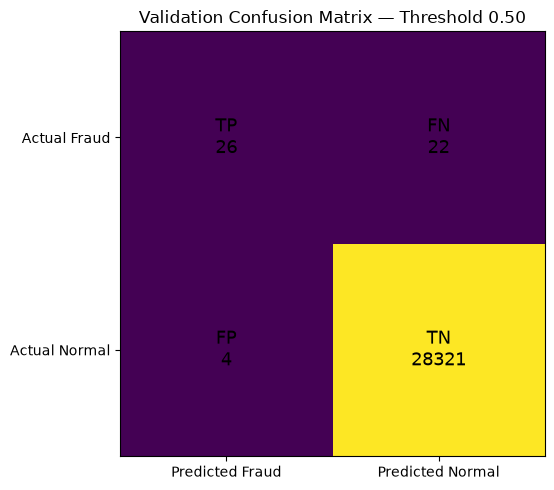

In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_val_prob = model.predict_proba(X_val_scaled)[:, 1]
y_val_pred_default = (y_val_prob >= 0.50).astype(int)

val_cm_default = confusion_matrix(y_val, y_val_pred_default)

TN, FP, FN, TP = val_cm_default.ravel()

print("Validation confusion-matrix counts at threshold 0.50")
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)

plot_fraud_first_confusion_matrix(
    val_cm_default,
    "Validation Confusion Matrix — Threshold 0.50"
)

plt.tight_layout()
plt.show()


In [47]:
val_precision_default = precision_score(y_val, y_val_pred_default)
val_recall_default = recall_score(y_val, y_val_pred_default)
val_f1_default = f1_score(y_val, y_val_pred_default)

print(f"Precision: {val_precision_default:.4f}")
print(f"Recall:    {val_recall_default:.4f}")
print(f"F1 Score:  {val_f1_default:.4f}")


Precision: 0.8667
Recall:    0.5417
F1 Score:  0.6667


### Metric interpretation


Precision =  TP/ TP+ FP


**Precision:** Of all transactions predicted as fraud how many were actually fraud?


Recall = TP / TP + FN


**Recall:** Of all real fraud transactions how many did the model catch?


F1 =  2PR/P+R

**F1:** Harmonic balance between precision and recall.


## 8. Probability-ranking performance: AP and PR-AUC




In [48]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc
)

val_ap = average_precision_score(y_val, y_val_prob)

val_curve_precision, val_curve_recall, _ = precision_recall_curve(
    y_val,
    y_val_prob
)

val_pr_auc = auc(val_curve_recall, val_curve_precision)

print(f"Validation Average Precision (AP): {val_ap:.4f}")
print(f"Validation PR-AUC:                 {val_pr_auc:.4f}")


Validation Average Precision (AP): 0.6449
Validation PR-AUC:                 0.6419


## 9. Tune the decision threshold using validation data only



In [49]:
thresholds = [0.50, 0.40, 0.30, 0.20]

threshold_results = []

for threshold in thresholds:
    y_val_pred_t = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred_t)
    recall = recall_score(y_val, y_val_pred_t)
    f1 = f1_score(y_val, y_val_pred_t)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results_df = pd.DataFrame(threshold_results)
threshold_results_df


,Threshold,Precision,Recall,F1
0,0.5,0.866667,0.541667,0.666667
1,0.4,0.875000,0.583333,0.700000
2,0.3,0.878788,0.604167,0.716049
3,0.2,0.857143,0.625000,0.722892


In [50]:
# Select the tested threshold with the highest validation F1 score
best_row = threshold_results_df.loc[
    threshold_results_df["F1"].idxmax()
]

selected_threshold = float(best_row["Threshold"])

print(f"Selected threshold based on validation F1: {selected_threshold:.2f}")
print()
print(best_row)


Selected threshold based on validation F1: 0.20

Threshold    0.200000
Precision    0.857143
Recall       0.625000
F1           0.722892
Name: 3, dtype: float64


## 10. Re-evaluate validation performance at the selected threshold

This is the fair validation result to compare with the final test result because both use the **same locked threshold**.

After this point, the threshold is considered fixed.


Selected threshold: 0.20
TN = 28320
FP = 5
FN = 18
TP = 30

Precision: 0.8571
Recall:    0.6250
F1 Score:  0.7229
PR-AUC:    0.6419
AP:        0.6449


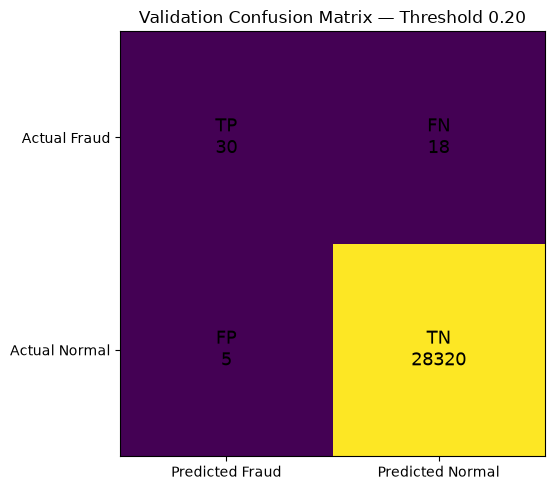

In [51]:
y_val_pred_selected = (y_val_prob >= selected_threshold).astype(int)

val_cm_selected = confusion_matrix(y_val, y_val_pred_selected)

val_precision = precision_score(y_val, y_val_pred_selected)
val_recall = recall_score(y_val, y_val_pred_selected)
val_f1 = f1_score(y_val, y_val_pred_selected)

TN, FP, FN, TP = val_cm_selected.ravel()

print(f"Selected threshold: {selected_threshold:.2f}")
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)
print()
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1 Score:  {val_f1:.4f}")
print(f"PR-AUC:    {val_pr_auc:.4f}")
print(f"AP:        {val_ap:.4f}")

plot_fraud_first_confusion_matrix(
    val_cm_selected,
    f"Validation Confusion Matrix — Threshold {selected_threshold:.2f}"
)

plt.tight_layout()
plt.show()


## 11. Final evaluation on the untouched test set

The model and threshold have already been chosen using training and validation data.

Now—and only now—we evaluate the final test set.

**No model choice or threshold change should be made because of these test results.**


Locked threshold: 0.20
TN = 28318
FP = 8
FN = 12
TP = 35

Precision: 0.8140
Recall:    0.7447
F1 Score:  0.7778
PR-AUC:    0.7421
AP:        0.7447


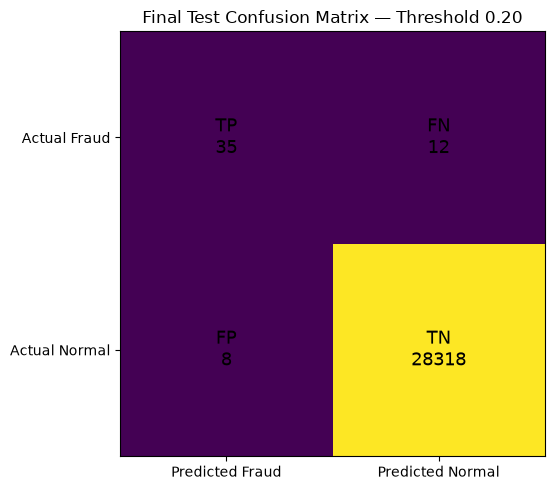

In [52]:
y_test_prob = model.predict_proba(X_test_scaled)[:, 1]
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

test_cm = confusion_matrix(y_test, y_test_pred)

test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

test_ap = average_precision_score(y_test, y_test_prob)

test_curve_precision, test_curve_recall, _ = precision_recall_curve(
    y_test,
    y_test_prob
)

test_pr_auc = auc(test_curve_recall, test_curve_precision)

TN, FP, FN, TP = test_cm.ravel()

print(f"Locked threshold: {selected_threshold:.2f}")
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)
print("TP =", TP)
print()
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"PR-AUC:    {test_pr_auc:.4f}")
print(f"AP:        {test_ap:.4f}")

plot_fraud_first_confusion_matrix(
    test_cm,
    f"Final Test Confusion Matrix — Threshold {selected_threshold:.2f}"
)

plt.tight_layout()
plt.show()


## 12. Final experiment visualization

The summary below compares:

1. Validation confusion matrix at the **selected threshold**.
2. Final test confusion matrix at the **same threshold**.
3. Threshold behavior on validation data.
4. Validation vs. test performance.

This avoids the earlier unfair comparison of validation at threshold 0.50 against test at threshold 0.20.


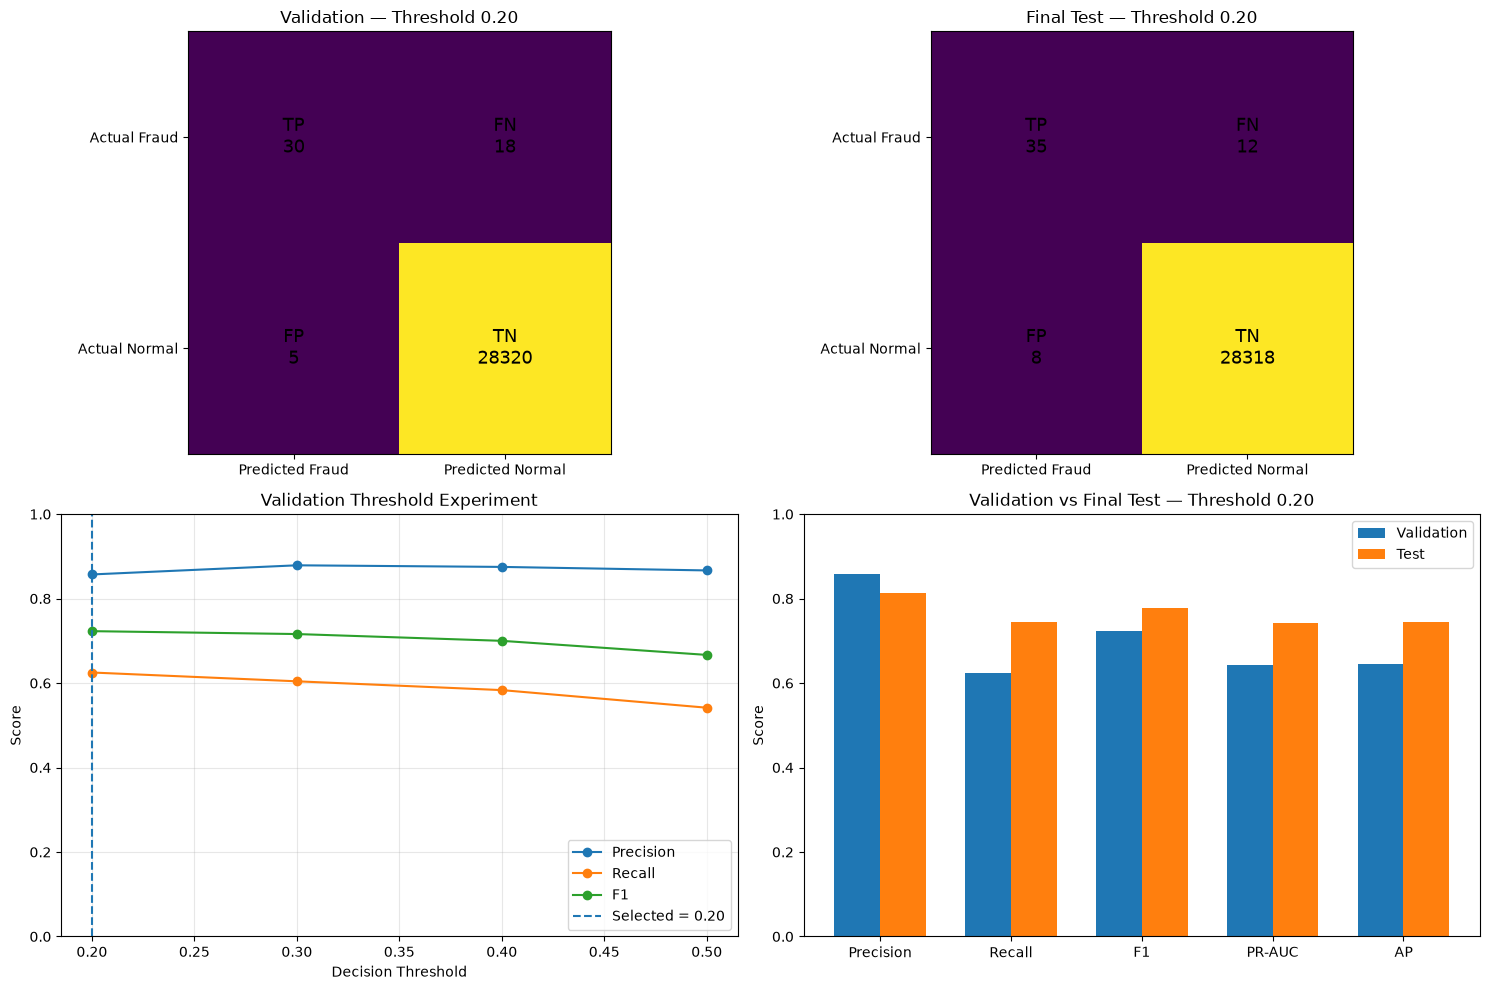

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Validation confusion matrix at selected threshold
plot_fraud_first_confusion_matrix(
    val_cm_selected,
    f"Validation — Threshold {selected_threshold:.2f}",
    ax=axes[0, 0]
)

# 2. Final test confusion matrix at the same threshold
plot_fraud_first_confusion_matrix(
    test_cm,
    f"Final Test — Threshold {selected_threshold:.2f}",
    ax=axes[0, 1]
)

# 3. Threshold experiment
axes[1, 0].plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Precision"],
    marker="o",
    label="Precision"
)

axes[1, 0].plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Recall"],
    marker="o",
    label="Recall"
)

axes[1, 0].plot(
    threshold_results_df["Threshold"],
    threshold_results_df["F1"],
    marker="o",
    label="F1"
)

axes[1, 0].axvline(
    selected_threshold,
    linestyle="--",
    label=f"Selected = {selected_threshold:.2f}"
)

axes[1, 0].set_title("Validation Threshold Experiment")
axes[1, 0].set_xlabel("Decision Threshold")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Fair validation vs test comparison
metric_names = ["Precision", "Recall", "F1", "PR-AUC", "AP"]

validation_metrics = [
    val_precision,
    val_recall,
    val_f1,
    val_pr_auc,
    val_ap
]

test_metrics = [
    test_precision,
    test_recall,
    test_f1,
    test_pr_auc,
    test_ap
]

x = np.arange(len(metric_names))
width = 0.35

axes[1, 1].bar(
    x - width / 2,
    validation_metrics,
    width=width,
    label="Validation"
)

axes[1, 1].bar(
    x + width / 2,
    test_metrics,
    width=width,
    label="Test"
)

axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(metric_names)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title(
    f"Validation vs Final Test — Threshold {selected_threshold:.2f}"
)
axes[1, 1].set_ylabel("Score")
axes[1, 1].legend()

plt.tight_layout()
plt.show()


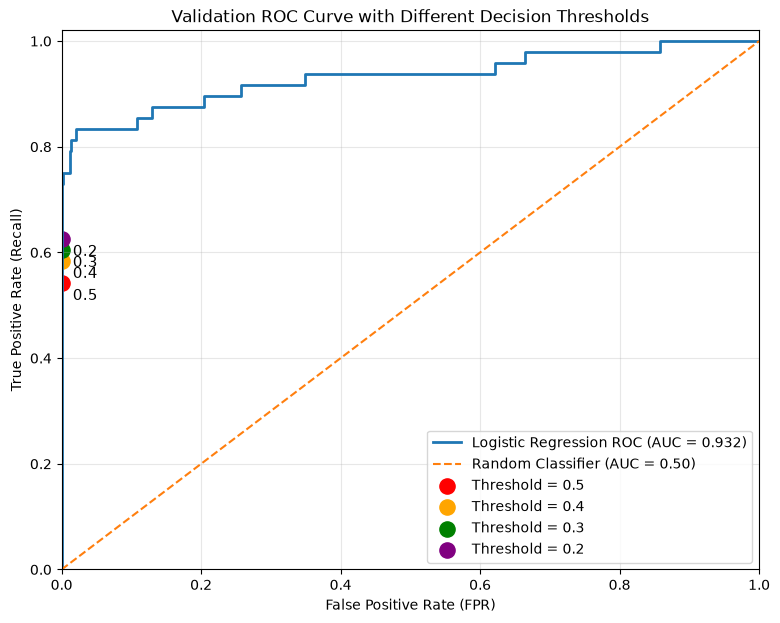

In [54]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

# --------------------------------------------------
# Full ROC curve using VALIDATION probabilities
# --------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(y_val, y_val_prob)
roc_auc = roc_auc_score(y_val, y_val_prob)

plt.figure(figsize=(9, 7))

# Full ROC curve = performance across ALL thresholds
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression ROC (AUC = {roc_auc:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.50)"
)


# --------------------------------------------------
# Highlight the thresholds WE tested
# --------------------------------------------------

tested_thresholds = [0.50, 0.40, 0.30, 0.20]

colors = ["red", "orange", "green", "purple"]

for threshold, color in zip(tested_thresholds, colors):

    # Convert probabilities to predictions
    y_pred_threshold = (y_val_prob >= threshold).astype(int)

    # Confusion matrix
    TN, FP, FN, TP = confusion_matrix(
        y_val,
        y_pred_threshold
    ).ravel()

    # ROC coordinates
    TPR = TP / (TP + FN)   # Recall / Sensitivity
    FPR = FP / (FP + TN)

    # Draw threshold point
    plt.scatter(
        FPR,
        TPR,
        s=120,
        color=color,
        label=f"Threshold = {threshold}"
    )

    # Write threshold value next to point
    plt.annotate(
        f"{threshold}",
        (FPR, TPR),
        xytext=(8, -12),
        textcoords="offset points",
        fontsize=11
    )


# --------------------------------------------------
# Final formatting
# --------------------------------------------------

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (Recall)")

plt.title(
    "Validation ROC Curve with Different Decision Thresholds"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

## 13. Research interpretation

This experiment demonstrates a leakage-aware machine-learning workflow:

**Clean data → split data → fit preprocessing on train only → train model → evaluate validation → choose threshold → lock choices → evaluate test once**

Important interpretation points:

- Accuracy is not the main metric because fraud is extremely rare.
- Precision measures the reliability of fraud alerts.
- Recall measures how much real fraud is caught.
- F1 balances precision and recall at one threshold.
- PR-AUC and AP summarize probability-ranking performance across thresholds.
- Threshold tuning changes the operating point but does not retrain the Logistic Regression model.
- The validation and test sets contain only a small number of fraud cases, so later cross-validation will be important for measuring robustness.

### Next controlled experiment

Use the same data protocol with **class-weighted Logistic Regression** and compare it against this standard Logistic Regression baseline before moving to XGBoost.
